# 06 — Final C-MAPSS RUL evaluation and report figures

**MMA3001 | NASA C-MAPSS turbofan Remaining Useful Life (RUL)**

This is a **results-only**, reproducible notebook. It loads CSV exports produced by notebooks 02, 04 and 05; it **does not retrain**, tune, or select models using official test labels. Its graphs are suitable for inclusion in the final report after checking labels and conclusions.

**Scope:** FD001–FD004 baseline vs Iteration 2, and FD002/FD004 Iteration 3 (unadjusted and conservative-offset). All baseline comparisons use the official **raw (uncapped) RUL** target; capped-horizon comparisons are labelled separately. A 100-cycle cap means predictions cannot reliably distinguish lifetimes above the cap.

**Outputs:** `results/final_evaluation/figures/*.png` and `*.pdf` plus numerical tables in `results/final_evaluation/tables/*.csv`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

DATASETS = ["FD001", "FD002", "FD003", "FD004"]
CAP = 100
NEAR_LIMIT = 30
FIG_DPI = 220

# Works when run from the repository root or from the notebooks/ folder.
HERE = Path.cwd().resolve()
ROOT = HERE.parent if HERE.name.lower() == "notebooks" else HERE
OUT = ROOT / "results" / "final_evaluation"
FIG_DIR = OUT / "figures"
TABLE_DIR = OUT / "tables"
for folder in (FIG_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Search typical locations used by earlier notebooks; edit INPUT_DIRS if needed.
INPUT_DIRS = [ROOT, ROOT / "results", ROOT / "results" / "tables", ROOT / "results" / "metrics",
              ROOT / "results" / "predictions", ROOT / "outputs", ROOT / "outputs" / "results",
              ROOT / "data" / "processed", HERE]

def find_csv(filename):
    candidates = [folder / filename for folder in INPUT_DIRS if (folder / filename).is_file()]
    if not candidates:
        candidates = sorted((x for x in ROOT.rglob(filename) if OUT not in x.parents), key=lambda x: (len(x.parts), str(x)))
    if not candidates:
        raise FileNotFoundError(f"Missing {filename}. Copy prior CSV exports into the repository/results directory, or add their directory to INPUT_DIRS.")
    if len(candidates) > 1:
        print(f"Multiple matches for {filename}; using {candidates[0]}")
    return candidates[0]

def load_csv(filename):
    path = find_csv(filename)
    print(f"Read {filename} from {path}")
    return pd.read_csv(path)

def savefig(name):
    plt.tight_layout()
    for ext in ("png", "pdf"):
        plt.savefig(FIG_DIR / f"{name}.{ext}", dpi=FIG_DPI, bbox_inches="tight")
    plt.show()

def savetable(df, name, index=False):
    df.to_csv(TABLE_DIR / f"{name}.csv", index=index)
    display(df.round(3))

plt.rcParams.update({"figure.figsize": (8.5, 5.0), "axes.grid": True,
                     "grid.alpha": .18, "font.size": 10})
print("Project root:", ROOT)
print("Figure output:", FIG_DIR)


Project root: /Users/aisha/mma3001-project
Figure output: /Users/aisha/mma3001-project/results/final_evaluation/figures


## A. Load and verify the exported predictions

The **prediction files** are the primary source for official-test metrics, so that all comparisons use the same formula and target. If the stored summary metrics disagree, the notebook flags it. An engine is the independent test unit (one final-window prediction per engine).

In [2]:
baseline, improved = {}, {}
for subset in DATASETS:
    baseline[subset] = load_csv(f"{subset.lower()}_test_predictions.csv")
    improved[subset] = load_csv(f"{subset.lower()}_improved_predictions.csv")
iter3_pred = load_csv("iteration5_official_test_predictions.csv")
iter3_metrics_saved = load_csv("iteration5_official_test_metrics.csv")
validation = load_csv("iteration5_validation_by_split.csv")
validation_summary = load_csv("iteration5_validation_summary.csv")
choices = load_csv("iteration5_model_choices.csv")
offsets = load_csv("iteration5_offset_validation.csv")

for subset in DATASETS:
    a, b = baseline[subset], improved[subset]
    required = {"engine_id", "actual_RUL", "predicted_RUL"}
    assert required.issubset(a) and required.issubset(b), subset
    assert a["engine_id"].is_unique and b["engine_id"].is_unique, subset
    joined = a[["engine_id", "actual_RUL"]].merge(
        b[["engine_id", "actual_RUL"]], on="engine_id", suffixes=("_baseline", "_improved"), validate="one_to_one")
    assert len(joined) == len(a) == len(b), f"Missing engines in {subset}"
    assert np.allclose(joined.actual_RUL_baseline, joined.actual_RUL_improved), f"Different RUL ground truth: {subset}"
    print(f"{subset}: {len(a)} aligned official test engines")

assert set(iter3_pred.dataset.unique()) == {"FD002", "FD004"}
assert not iter3_pred.duplicated(["dataset", "engine_id"]).any()
for subset in ("FD002", "FD004"):
    old = improved[subset][["engine_id", "actual_RUL"]]
    new = iter3_pred.loc[iter3_pred.dataset.eq(subset), ["engine_id", "actual_RUL"]]
    merged = old.merge(new, on="engine_id", suffixes=("_i2", "_i3"), validate="one_to_one")
    assert len(merged) == len(old) == len(new)
    assert np.allclose(merged.actual_RUL_i2, merged.actual_RUL_i3)
print("All cross-iteration engine IDs and RUL labels match.")

Read fd001_test_predictions.csv from /Users/aisha/mma3001-project/results/metrics/fd001_test_predictions.csv
Read fd001_improved_predictions.csv from /Users/aisha/mma3001-project/results/metrics/fd001_improved_predictions.csv
Read fd002_test_predictions.csv from /Users/aisha/mma3001-project/results/metrics/fd002_test_predictions.csv
Read fd002_improved_predictions.csv from /Users/aisha/mma3001-project/results/metrics/fd002_improved_predictions.csv
Read fd003_test_predictions.csv from /Users/aisha/mma3001-project/results/metrics/fd003_test_predictions.csv
Read fd003_improved_predictions.csv from /Users/aisha/mma3001-project/results/metrics/fd003_improved_predictions.csv
Read fd004_test_predictions.csv from /Users/aisha/mma3001-project/results/metrics/fd004_test_predictions.csv
Read fd004_improved_predictions.csv from /Users/aisha/mma3001-project/results/metrics/fd004_improved_predictions.csv
Read iteration5_official_test_predictions.csv from /Users/aisha/mma3001-project/results/metrics/

## B. Recalculate all final metrics consistently

Definitions: signed error = predicted − actual; **positive bias = optimistic RUL overestimate**. RMSE, MAE and R² are computed for both raw RUL and the common 100-cycle target. The latter answers a *different question* and must not be directly compared to raw-RUL scores.

In [3]:
def metric_row(subset, model, truth, pred):
    y = np.asarray(truth, dtype=float)
    p = np.asarray(pred, dtype=float)
    assert len(y) and np.isfinite(y).all() and np.isfinite(p).all()
    err = p - y
    den = ((y-y.mean())**2).sum()
    cap_y = np.minimum(y, CAP)
    cap_err = p - cap_y
    cap_den = ((cap_y-cap_y.mean())**2).sum()
    near = y <= NEAR_LIMIT
    return {"dataset": subset, "model": model, "n_engines": len(y),
            "raw_MAE": np.abs(err).mean(), "raw_RMSE": np.sqrt(np.mean(err**2)),
            "raw_R2": 1 - (err**2).sum()/den if den > 0 else np.nan,
            "raw_bias": err.mean(),
            "common100_MAE": np.abs(cap_err).mean(), "common100_RMSE": np.sqrt(np.mean(cap_err**2)),
            "common100_R2": 1 - (cap_err**2).sum()/cap_den if cap_den > 0 else np.nan,
            "near_n": int(near.sum()),
            "near_MAE": np.abs(err[near]).mean() if near.any() else np.nan,
            "near_bias": err[near].mean() if near.any() else np.nan,
            "near_over_fraction": (err[near] > 0).mean() if near.any() else np.nan}

rows=[]
for subset in DATASETS:
    for label, data in [("Baseline", baseline[subset]), ("Iteration 2", improved[subset])]:
        rows.append(metric_row(subset, label, data.actual_RUL, data.predicted_RUL))
for subset in ("FD002", "FD004"):
    data = iter3_pred.query("dataset == @subset")
    rows.append(metric_row(subset, "Iteration 3 — unadjusted", data.actual_RUL, data.predicted_unadjusted))
    rows.append(metric_row(subset, "Iteration 3 — conservative", data.actual_RUL, data.predicted_adjusted))
metrics = pd.DataFrame(rows)
savetable(metrics, "official_test_metrics_recalculated")

for _, r in iter3_metrics_saved.iterrows():
    model = "Iteration 3 — conservative" if r["method"] == "conservative_offset" else "Iteration 3 — unadjusted"
    ours = metrics.query("dataset == @r.dataset and model == @model").iloc[0]
    for col in ("raw_MAE", "raw_RMSE", "common100_RMSE", "near_MAE", "near_bias", "near_over_fraction"):
        assert np.isclose(r[col], ours[col], atol=1e-6), f"Mismatch in {r.dataset} {model} {col}"
print("Iteration 3 exported metrics verified against predictions.")

,dataset,model,n_engines,raw_MAE,raw_RMSE,raw_R2,raw_bias,common100_MAE,common100_RMSE,common100_R2,near_n,near_MAE,near_bias,near_over_fraction
0,FD001,Baseline,100,20.132,26.654,0.589,9.746,23.356,31.101,0.171,25,9.612,8.456,0.720
1,FD001,Iteration 2,100,13.412,18.260,0.807,-7.616,6.622,9.482,0.923,25,5.438,4.694,0.720
2,FD002,Baseline,259,20.213,28.099,0.727,4.623,24.611,33.666,0.094,61,6.231,3.466,0.689
3,FD002,Iteration 2,259,23.601,34.241,0.595,-14.855,8.964,12.399,0.877,61,7.495,5.712,0.754
4,FD003,Baseline,100,25.981,35.422,0.268,19.822,30.436,42.870,-0.770,20,5.992,4.582,0.750
5,FD003,Iteration 2,100,14.613,19.724,0.773,-6.188,6.903,10.359,0.897,20,3.855,3.229,0.850
6,FD004,Baseline,248,28.067,39.455,0.476,16.628,38.513,55.211,-1.525,53,9.109,8.150,0.792
7,FD004,Iteration 2,248,27.088,37.373,0.530,-16.583,9.963,14.009,0.837,53,12.151,11.755,0.925
8,FD002,Iteration 3 — unadjusted,259,24.092,34.446,0.590,-14.832,9.455,12.470,0.876,61,8.434,7.759,0.820
9,FD002,Iteration 3 — conservative,259,25.479,36.876,0.530,-19.832,10.842,13.508,0.854,61,5.791,2.759,0.689


Iteration 3 exported metrics verified against predictions.


## C. Figure 1 — Raw-RUL performance across experiments

This is the main model comparison. Lower RMSE and MAE are better. FD001 and FD003 have no Iteration 3 results; missing bars are intentionally omitted.

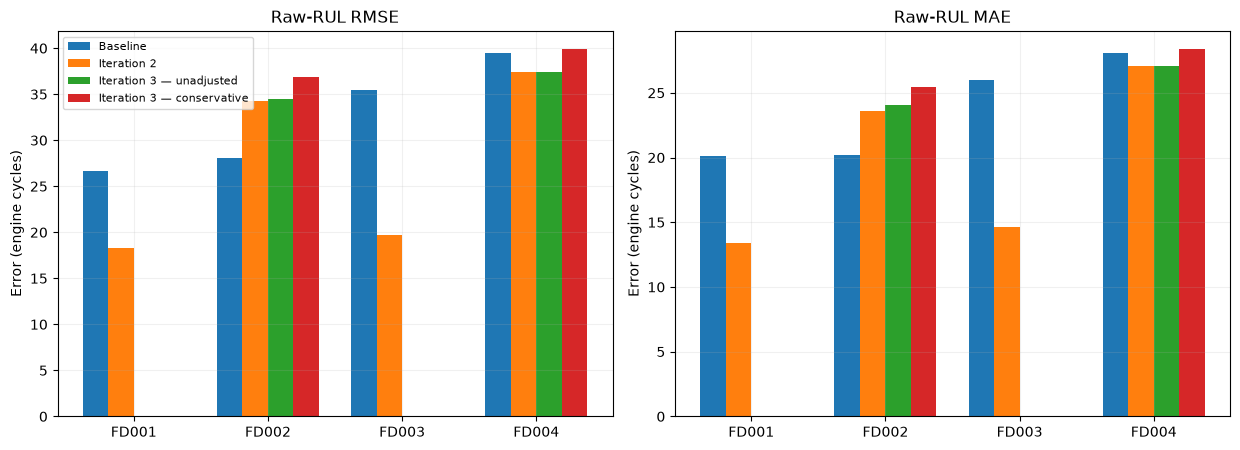

model,dataset,Baseline,Iteration 2,Iteration 3 — conservative,Iteration 3 — unadjusted,Iteration2_vs_baseline_reduction_pct
0,FD001,26.654,18.260,NaN,NaN,31.491
1,FD002,28.099,34.241,36.876,34.446,-21.861
2,FD003,35.422,19.724,NaN,NaN,44.317
3,FD004,39.455,37.373,39.874,37.408,5.278


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5,4.6))
models = ["Baseline", "Iteration 2", "Iteration 3 — unadjusted", "Iteration 3 — conservative"]
for ax, key, title in zip(axes, ["raw_RMSE", "raw_MAE"], ["Raw-RUL RMSE", "Raw-RUL MAE"]):
    x=np.arange(4); width=.19
    for i,model in enumerate(models):
        ds=metrics.query("model == @model").set_index("dataset")[key].reindex(DATASETS)
        ax.bar(x+(i-1.5)*width, ds, width, label=model)
    ax.set_xticks(x, DATASETS); ax.set_ylabel("Error (engine cycles)"); ax.set_title(title)
    ax.set_ylim(bottom=0)
axes[0].legend(fontsize=8, loc="upper left")
savefig("01_official_raw_rul_model_comparison")

compare = metrics.pivot(index="dataset", columns="model", values="raw_RMSE")
compare["Iteration2_vs_baseline_reduction_pct"] = 100*(compare["Baseline"]-compare["Iteration 2"])/compare["Baseline"]
savetable(compare.reset_index(), "raw_rmse_comparison")

## D. Figure 2 — Raw vs capped-horizon error

Same predictions, different evaluation target. Never describe 100 capped cycles as a precise prediction of lifetime when actual RUL exceeds 100.

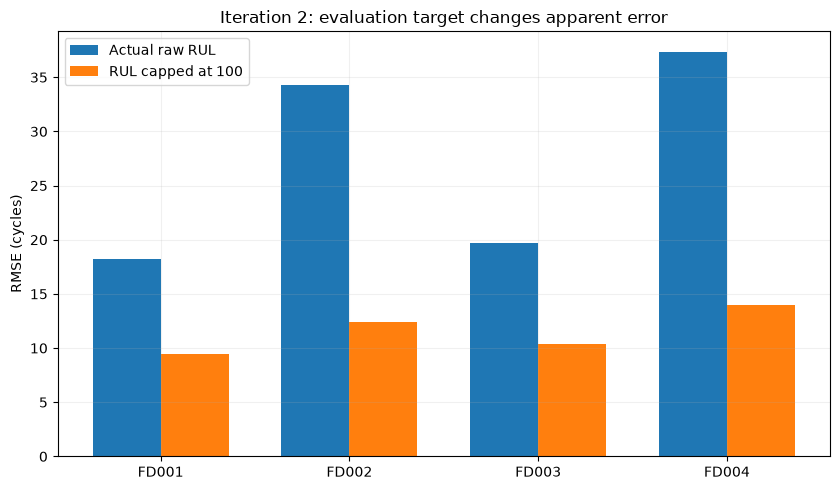

In [5]:
i2 = metrics.query("model == 'Iteration 2'").set_index("dataset").loc[DATASETS]
x=np.arange(len(DATASETS)); width=.36
fig,ax=plt.subplots()
ax.bar(x-width/2,i2.raw_RMSE,width,label="Actual raw RUL")
ax.bar(x+width/2,i2.common100_RMSE,width,label="RUL capped at 100")
ax.set_xticks(x,DATASETS); ax.set_ylabel("RMSE (cycles)")
ax.set_title("Iteration 2: evaluation target changes apparent error")
ax.legend()
savefig("02_raw_vs_capped_rul_rmse")

## E. Figures 3–6 — Actual vs predicted RUL, by dataset

Each dataset has matched baseline and Iteration 2 predictions. A 45° dashed line means perfect prediction; values above indicate RUL overestimation. Each plot also marks the 100-cycle prediction horizon.

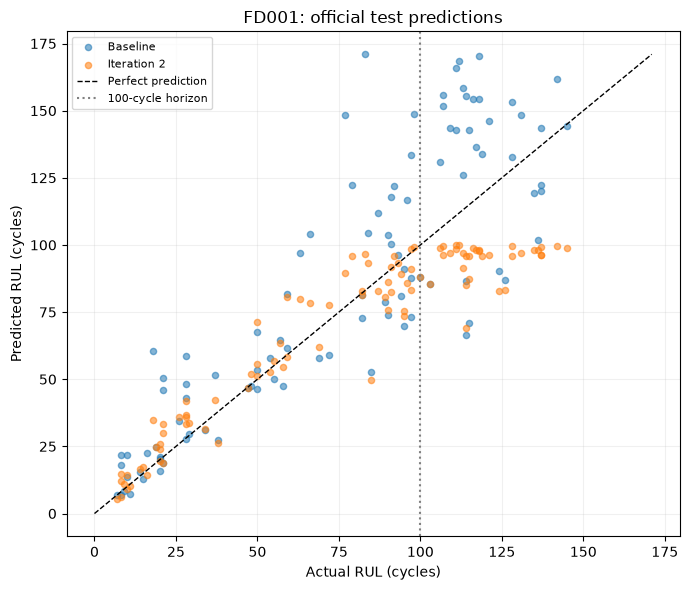

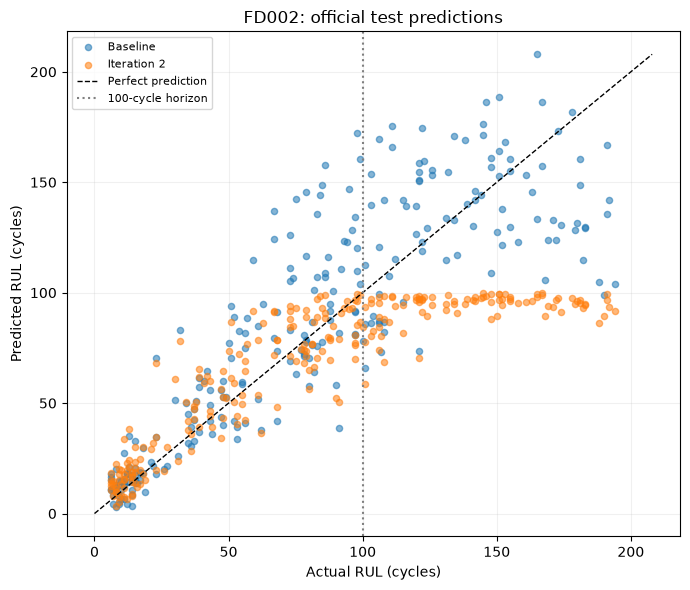

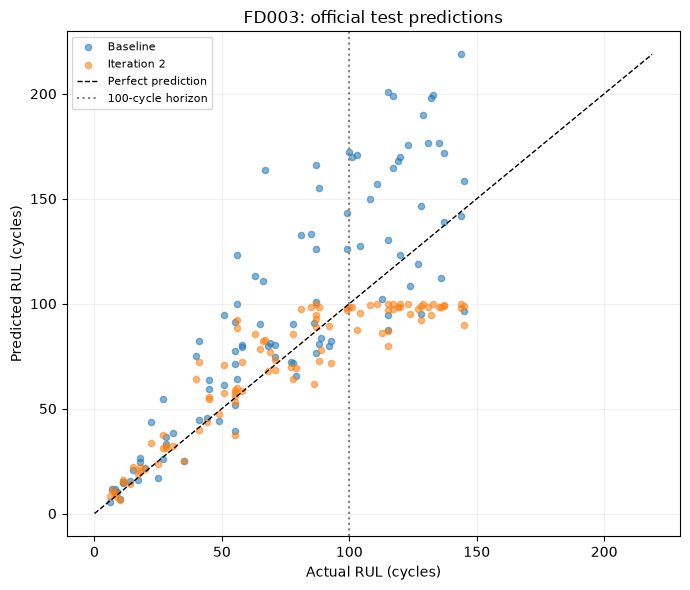

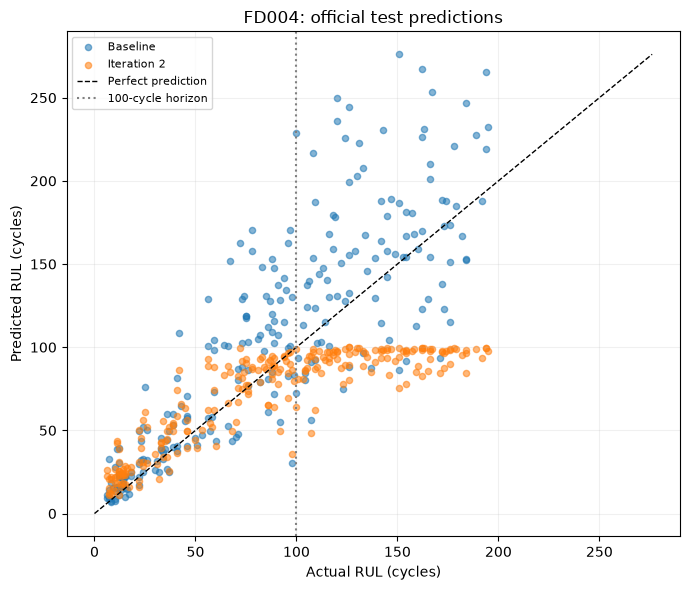

In [6]:
for subset in DATASETS:
    fig,ax=plt.subplots(figsize=(7,6))
    for name,data in (("Baseline",baseline[subset]),("Iteration 2",improved[subset])):
        ax.scatter(data.actual_RUL, data.predicted_RUL, s=20, alpha=.55, label=name)
    vmax=max(baseline[subset][["actual_RUL","predicted_RUL"]].to_numpy().max(),
             improved[subset][["actual_RUL","predicted_RUL"]].to_numpy().max())
    ax.plot([0,vmax],[0,vmax],"--",color="black",lw=1,label="Perfect prediction")
    ax.axvline(CAP,color="grey",ls=":",label="100-cycle horizon")
    ax.set(xlabel="Actual RUL (cycles)",ylabel="Predicted RUL (cycles)",title=f"{subset}: official test predictions")
    ax.legend(fontsize=8)
    savefig(f"03_actual_vs_predicted_{subset.lower()}")

## F. Figure 7 — Errors by actual RUL range

Using a common set of mutually exclusive **raw-RUL bands** (0–30, 31–60, 61–100, 101–150 and 151+). Bands with no engines are omitted; the CSV export includes the sample count to avoid over-interpreting small groups.

,dataset,model,band,n,MAE,bias
0,FD001,Baseline,0–30,25,9.612,8.456
1,FD001,Baseline,31–60,14,7.534,2.775
2,FD001,Baseline,61–100,28,24.677,11.832
3,FD001,Baseline,101–150,33,29.590,11.910
4,FD001,Iteration 2,0–30,25,5.438,4.694
5,FD001,Iteration 2,31–60,14,6.275,3.378
6,FD001,Iteration 2,61–100,28,9.471,-2.643
7,FD001,Iteration 2,101–150,33,25.826,-25.826
8,FD002,Baseline,0–30,61,6.231,3.466
9,FD002,Baseline,31–60,41,15.472,10.662


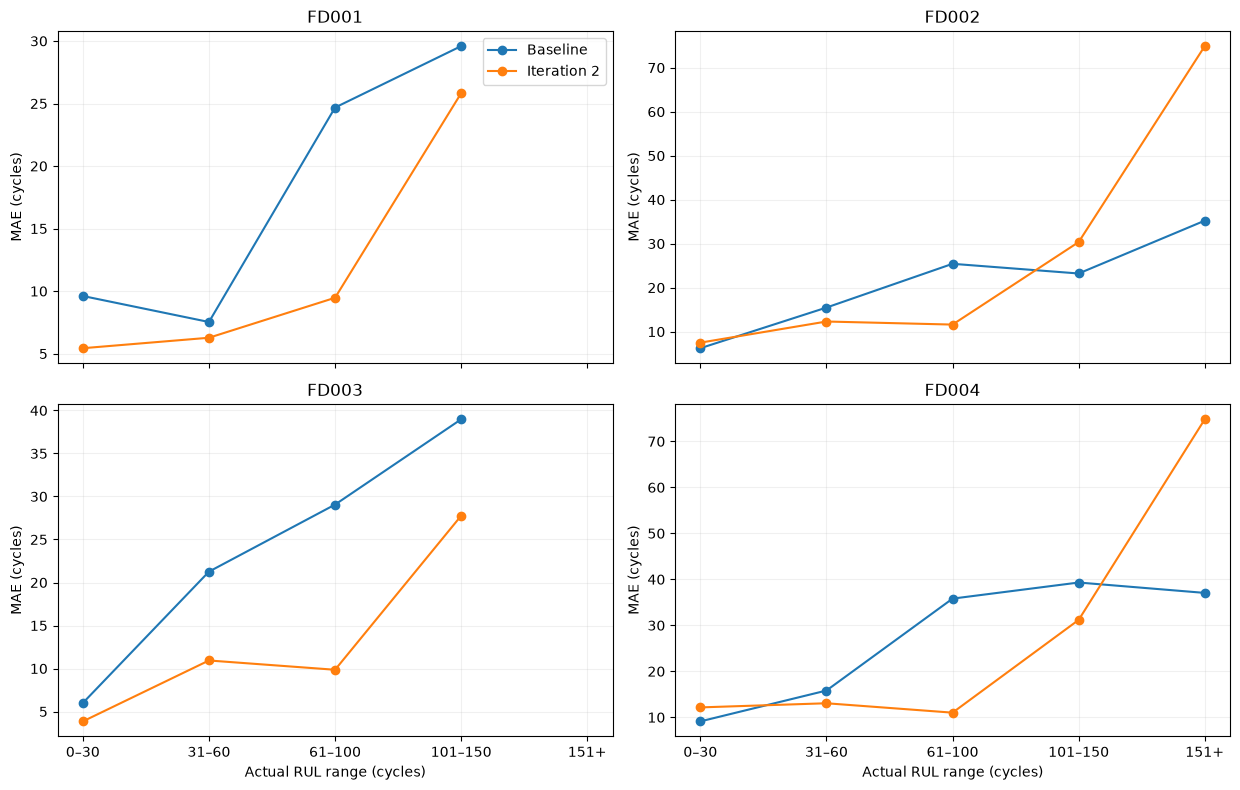

In [7]:
bins=[-np.inf,30,60,100,150,np.inf]
labels=["0–30","31–60","61–100","101–150","151+"]
records=[]
for subset in DATASETS:
    for label,data in (("Baseline",baseline[subset]),("Iteration 2",improved[subset])):
        frame=data.copy()
        frame["band"]=pd.cut(frame.actual_RUL,bins=bins,labels=labels)
        frame["signed_error"]=frame.predicted_RUL-frame.actual_RUL
        for band,group in frame.groupby("band", observed=True):
            records.append(dict(dataset=subset,model=label,band=str(band),n=len(group),
                                MAE=group.signed_error.abs().mean(),bias=group.signed_error.mean()))
bands_df=pd.DataFrame(records)
savetable(bands_df,"error_by_rul_band")
fig,axes=plt.subplots(2,2,figsize=(12.5,8.0),sharex=True)
for ax,subset in zip(axes.flat,DATASETS):
    for label in ("Baseline","Iteration 2"):
        d=bands_df.query("dataset == @subset and model == @label").set_index("band").reindex(labels)
        ax.plot(labels,d.MAE,marker="o",label=label)
    ax.set_title(subset); ax.set_ylabel("MAE (cycles)")
axes[0,0].legend()
for ax in axes[-1,:]: ax.set_xlabel("Actual RUL range (cycles)")
savefig("04_error_by_rul_band")

## G. Figure 8 — Error bias and near-failure overestimation

Positive bias is potentially consequential because it means the model predicts more life than is actually remaining. Near-failure metrics use **actual RUL ≤ 30**; they are diagnostics, **not a certified maintenance risk guarantee**.

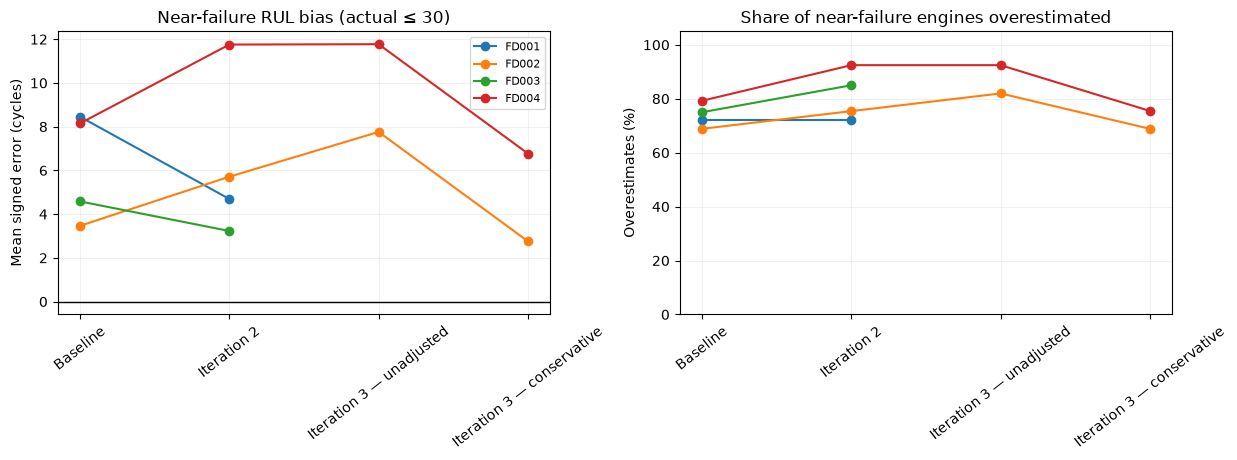

,dataset,model,near_n,near_MAE,near_bias,near_over_fraction
0,FD001,Baseline,25,9.612,8.456,0.720
1,FD001,Iteration 2,25,5.438,4.694,0.720
2,FD002,Baseline,61,6.231,3.466,0.689
3,FD002,Iteration 2,61,7.495,5.712,0.754
4,FD003,Baseline,20,5.992,4.582,0.750
5,FD003,Iteration 2,20,3.855,3.229,0.850
6,FD004,Baseline,53,9.109,8.150,0.792
7,FD004,Iteration 2,53,12.151,11.755,0.925
8,FD002,Iteration 3 — unadjusted,61,8.434,7.759,0.820
9,FD002,Iteration 3 — conservative,61,5.791,2.759,0.689


In [8]:
near = metrics[metrics.model.isin(["Baseline","Iteration 2","Iteration 3 — unadjusted","Iteration 3 — conservative"])].copy()
fig,axs=plt.subplots(1,2,figsize=(12.5,4.7))
for subset in DATASETS:
    d=near.query("dataset == @subset")
    axs[0].plot(d.model,d.near_bias,marker="o",label=subset)
    axs[1].plot(d.model,100*d.near_over_fraction,marker="o",label=subset)
for a in axs: a.tick_params(axis="x",rotation=38)
axs[0].axhline(0,color="black",lw=1)
axs[0].set(ylabel="Mean signed error (cycles)",title="Near-failure RUL bias (actual ≤ 30)")
axs[1].set(ylabel="Overestimates (%)",title="Share of near-failure engines overestimated",ylim=(0,105))
axs[0].legend(fontsize=8)
savefig("05_near_failure_bias_and_overestimation")
savetable(near[["dataset","model","near_n","near_MAE","near_bias","near_over_fraction"]],"near_failure_model_comparison")

## H. Figures 9–10 — Iteration 3 conservative adjustment trade-off

The fixed subtraction was chosen from validation experiments. These official-test comparisons are **descriptive only** and must not be used to retune the offset. The effect on raw RMSE and near-failure MAE is shown separately.

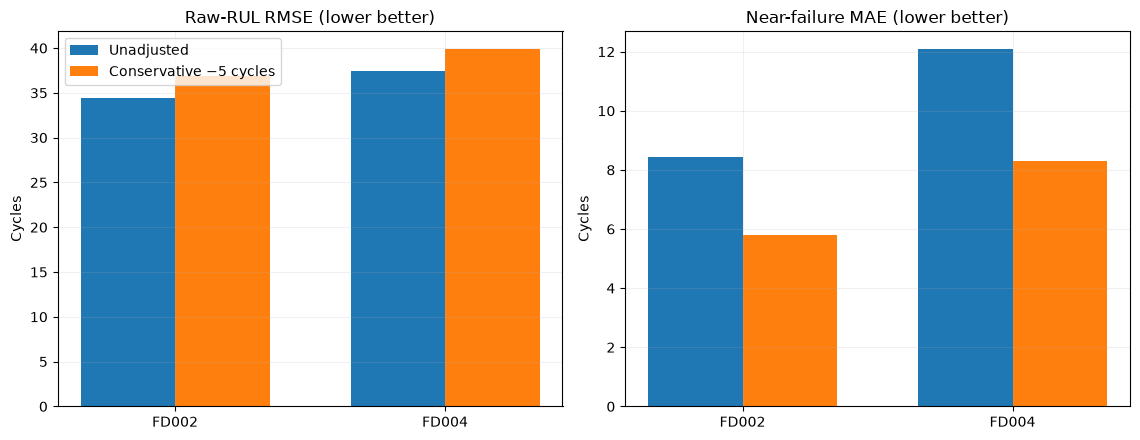

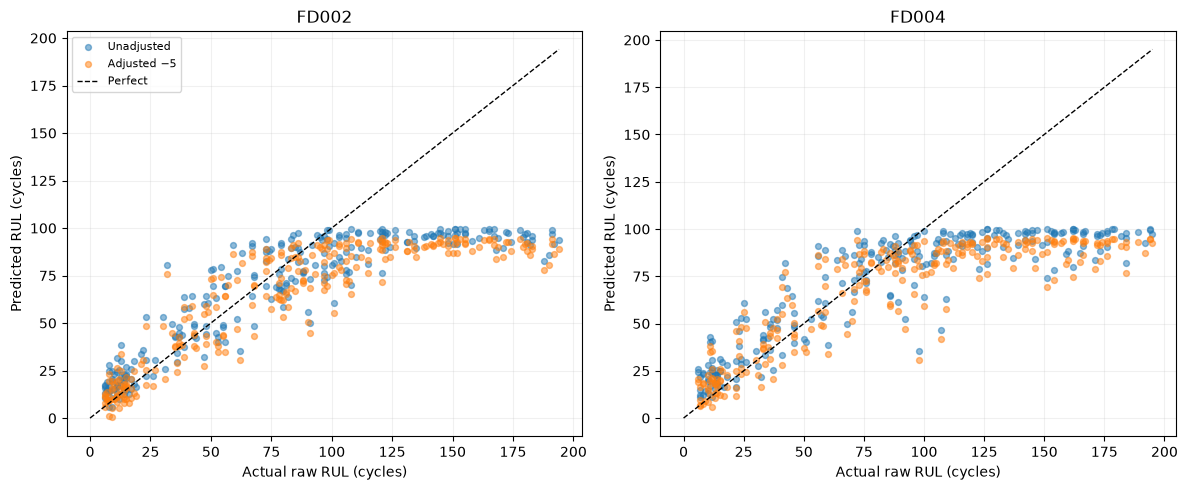

In [9]:
i3 = metrics[metrics.model.str.startswith("Iteration 3")]
fig,axes=plt.subplots(1,2,figsize=(11.5,4.5))
x=np.arange(2); width=.35
for ax,key,title in [(axes[0],"raw_RMSE","Raw-RUL RMSE (lower better)"), (axes[1],"near_MAE","Near-failure MAE (lower better)")]:
    u=i3.query("model == 'Iteration 3 — unadjusted'").set_index("dataset").loc[["FD002","FD004"],key]
    c=i3.query("model == 'Iteration 3 — conservative'").set_index("dataset").loc[["FD002","FD004"],key]
    ax.bar(x-width/2,u,width,label="Unadjusted")
    ax.bar(x+width/2,c,width,label="Conservative −5 cycles")
    ax.set_xticks(x,["FD002","FD004"]); ax.set_ylabel("Cycles"); ax.set_title(title)
axes[0].legend()
savefig("06_conservative_offset_tradeoff")

fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,subset in zip(axes,["FD002","FD004"]):
    d=iter3_pred.query("dataset == @subset")
    ax.scatter(d.actual_RUL,d.predicted_unadjusted,s=18,alpha=.5,label="Unadjusted")
    ax.scatter(d.actual_RUL,d.predicted_adjusted,s=18,alpha=.5,label="Adjusted −5")
    upper=max(d.actual_RUL.max(),d.predicted_unadjusted.max())
    ax.plot([0,upper],[0,upper],"k--",lw=1,label="Perfect")
    ax.set(title=subset,xlabel="Actual raw RUL (cycles)",ylabel="Predicted RUL (cycles)")
axes[0].legend(fontsize=8)
savefig("07_iteration3_adjusted_predictions")

## I. Figure 11 — Repeat-split validation stability

Each dot is an engine-separated validation split (not a repeated official test). Compare the spread **within a common target**, and do not interpret test scores as validation scores. This section visualises the same fixed candidate settings from notebook 05.

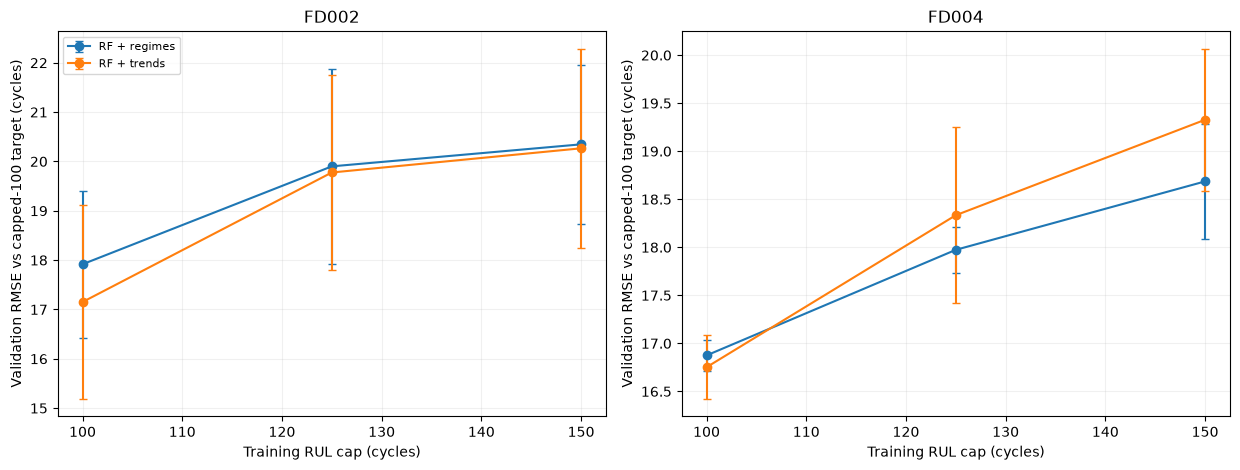

,dataset,variant,cap,risk_score,risk_sd,common100_RMSE,raw_RMSE,near_MAE,near_bias
0,FD002,RF + trends,100,17.166,1.810,17.151,22.221,13.726,13.726
1,FD002,RF + regimes,100,17.702,1.608,17.916,22.810,12.298,12.298
2,FD002,RF + regimes,125,19.294,1.813,19.900,24.053,12.367,12.367
3,FD002,RF + trends,125,19.569,1.874,19.776,23.702,14.674,14.667
4,FD002,RF + regimes,150,19.794,1.555,20.346,25.960,13.023,13.023
5,FD002,RF + trends,150,19.901,1.777,20.266,25.059,14.716,14.715
6,FD004,RF + trends,100,16.638,1.110,16.752,36.146,10.837,10.193
7,FD004,RF + regimes,100,16.651,0.897,16.875,36.077,9.190,8.486
8,FD004,RF + regimes,125,17.641,0.602,17.974,32.831,9.415,8.685
9,FD004,RF + trends,125,18.066,1.774,18.334,32.698,11.663,11.062


,dataset,variant,cap,risk_score,risk_sd,common100_RMSE,raw_RMSE,near_MAE,near_bias
0,FD002,RF + trends,100,17.166,1.81,17.151,22.221,13.726,13.726
1,FD004,RF + trends,100,16.638,1.11,16.752,36.146,10.837,10.193


In [10]:
fig,axes=plt.subplots(1,2,figsize=(12.5,4.8))
for ax,subset in zip(axes,["FD002","FD004"]):
    d=validation.query("dataset == @subset").copy()
    for name,g in d.groupby("variant"):
        avg=g.groupby("cap")["common100_RMSE"].agg(["mean","std"]).sort_index()
        ax.errorbar(avg.index,avg["mean"],yerr=avg["std"],marker="o",capsize=3,label=name)
    ax.set(title=subset,xlabel="Training RUL cap (cycles)",ylabel="Validation RMSE vs capped-100 target (cycles)")
axes[0].legend(fontsize=8)
savefig("08_validation_cap_sensitivity")
savetable(validation_summary.sort_values(["dataset","risk_score"]),"validation_configs_ranked")
savetable(choices,"validation_selected_models")

## J. Figure 12 — Error distributions (official test)

Residuals = predicted − actual. The zero line indicates an unbiased individual prediction. The histograms reveal how aggregate RMSE can hide large optimistic or pessimistic errors.

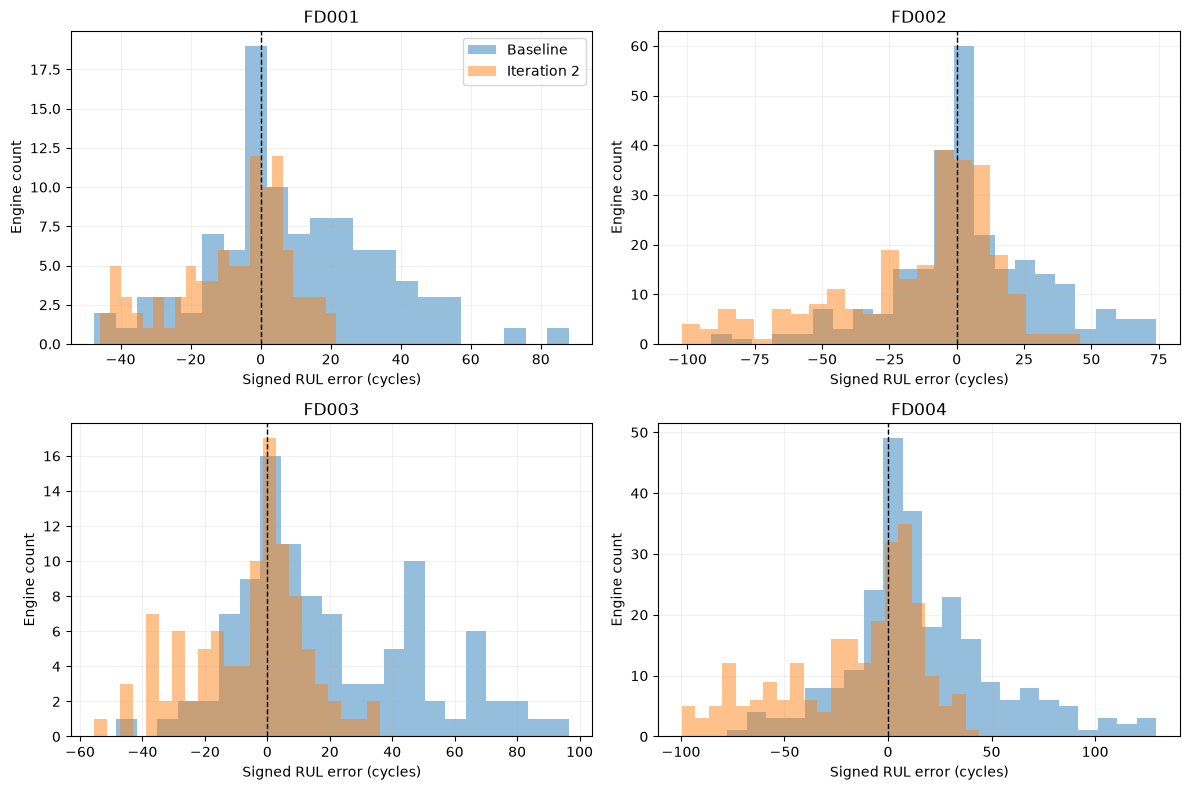

In [11]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,subset in zip(axes.flat,DATASETS):
    for label,data in (("Baseline",baseline[subset]),("Iteration 2",improved[subset])):
        resid=data.predicted_RUL-data.actual_RUL
        ax.hist(resid,bins=22,alpha=.48,label=label)
    ax.axvline(0,color="black",ls="--",lw=1)
    ax.set(title=subset,xlabel="Signed RUL error (cycles)",ylabel="Engine count")
axes[0,0].legend()
savefig("09_official_test_error_histograms")

## K. Validation-selected calibration — FD002 and FD004

This section uses outputs from `07_rul_validation_calibration.ipynb`. **Offsets are selected using repeated engine-separated validation predictions only**, with an allowed validation raw-RUL RMSE increase of at most 5%. The official test set is then used only to assess the locked adjustment. This is a post-processing study, **not a newly trained model**.

The analysis compares the unadjusted Iteration 3 predictions with validation-calibrated predictions on **identical official test engines**. Near failure means actual RUL ≤ 30 cycles. Signed bias is prediction minus actual RUL (positive = optimistic). A smaller near-failure MAE may come at the cost of worse global RMSE. The calibration offset is **not** necessarily the earlier fixed 5-cycle offset.

Figures: calibration trade-off (validation); near-failure bias and overestimation rate (official test); near-failure MAE and full-life RMSE (official test). Tables are exported for direct use in the report.


In [12]:
# Run notebook 07 first. If its outputs are missing, this section skips rather than fabricating results.
cal_names = ["calibration_selected_offsets.csv", "calibration_validation_grid.csv",
             "calibration_official_test_metrics.csv", "calibration_official_test_predictions.csv"]
cal_files = {}
for filename in cal_names:
    try:
        cal_files[filename] = find_csv(filename)
    except FileNotFoundError:
        pass
CAL_READY = len(cal_files) == len(cal_names)
if not CAL_READY:
    print("Calibration exports missing:", sorted(set(cal_names) - set(cal_files)))
    print("Run 07_rul_validation_calibration.ipynb, then rerun this cell and the following calibration cells.")
else:
    cal_selected = pd.read_csv(cal_files["calibration_selected_offsets.csv"])
    cal_grid = pd.read_csv(cal_files["calibration_validation_grid.csv"])
    cal_metrics = pd.read_csv(cal_files["calibration_official_test_metrics.csv"])
    cal_predictions = pd.read_csv(cal_files["calibration_official_test_predictions.csv"])
    expected_metrics = {"dataset", "method", "raw_RMSE", "near_MAE", "near_bias", "near_over_fraction"}
    expected_preds = {"dataset", "engine_id", "actual_RUL", "predicted_unadjusted", "predicted_calibrated"}
    assert expected_metrics.issubset(cal_metrics.columns), "Calibration metrics schema differs; check notebook 07 exports"
    assert expected_preds.issubset(cal_predictions.columns), "Calibration predictions schema differs; check notebook 07 exports"
    assert set(cal_metrics.dataset.unique()) == {"FD002", "FD004"}
    assert not cal_predictions.duplicated(["dataset", "engine_id"]).any()
    # Check labels and original predictions against the official Iteration 3 file.
    reference = iter3_pred[["dataset", "engine_id", "actual_RUL", "predicted_unadjusted"]]
    merged = cal_predictions.merge(reference, on=["dataset", "engine_id"], suffixes=("_cal", "_i3"), validate="one_to_one")
    assert len(merged) == len(cal_predictions) == len(reference)
    assert np.allclose(merged.actual_RUL_cal, merged.actual_RUL_i3)
    assert np.allclose(merged.predicted_unadjusted_cal, merged.predicted_unadjusted_i3)
    # Independently verify exported calibration test metrics.
    for dataset in ("FD002", "FD004"):
        data = cal_predictions.query("dataset == @dataset")
        for method, column in [("Unadjusted", "predicted_unadjusted"),
                               ("Validation-calibrated", "predicted_calibrated")]:
            calc = metric_row(dataset, method, data.actual_RUL, data[column])
            ref = cal_metrics.query("dataset == @dataset and method == @method").iloc[0]
            for key in ("raw_RMSE", "near_MAE", "near_bias", "near_over_fraction"):
                assert np.isclose(calc[key], ref[key], atol=1e-6), f"Mismatch: {dataset} {method} {key}"
    savetable(cal_selected, "calibration_selected_offsets")
    savetable(cal_metrics, "calibration_official_test_metrics_verified")
    print("Calibration engine alignment and metrics verified; offsets were selected on validation.")

Calibration exports missing: ['calibration_official_test_metrics.csv', 'calibration_official_test_predictions.csv', 'calibration_selected_offsets.csv', 'calibration_validation_grid.csv']
Run 07_rul_validation_calibration.ipynb, then rerun this cell and the following calibration cells.


In [13]:
if CAL_READY:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
    for ax, dataset in zip(axes, ["FD002", "FD004"]):
        d = cal_grid.loc[cal_grid.dataset.eq(dataset)].sort_values("offset")
        ax.plot(d.raw_RMSE, d.near_MAE, "o-", alpha=.85, label="Validation offsets")
        for offset in (0, 5, 10, 15):
            t = d.loc[d.offset.eq(offset)]
            if not t.empty:
                r = t.iloc[0]
                ax.annotate(str(offset), (r.raw_RMSE, r.near_MAE), xytext=(4, 5), textcoords="offset points", fontsize=9)
        sel = cal_selected.loc[cal_selected.dataset.eq(dataset)].iloc[0]
        chosen = d.loc[d.offset.eq(sel.selected_offset)].iloc[0]
        ax.scatter([chosen.raw_RMSE], [chosen.near_MAE], marker="*", s=220, label="Validation-selected", zorder=5)
        ax.set(title=f"{dataset} — validation calibration trade-off",
               xlabel="Validation raw-RUL RMSE (cycles)", ylabel="Validation near-failure MAE (cycles)")
        ax.legend(fontsize=8)
    savefig("11_calibration_validation_tradeoff")

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    pairs = [("raw_RMSE", "Overall raw-RUL RMSE", "cycles"),
             ("near_MAE", "Near-failure MAE (RUL ≤ 30)", "cycles"),
             ("near_bias", "Near-failure signed bias", "cycles"),
             ("near_over_fraction", "Near-failure overestimation frequency", "fraction")]
    methods = ["Unadjusted", "Validation-calibrated"]
    for ax, (metric, title, units) in zip(axes.flat, pairs):
        vals = cal_metrics.pivot(index="dataset", columns="method", values=metric).loc[["FD002", "FD004"]]
        x = np.arange(len(vals)); width = .35
        for j, method in enumerate(methods):
            ax.bar(x+(j-.5)*width, vals[method].to_numpy(), width, label=method)
        ax.set_xticks(x, vals.index)
        ax.set(title=title, ylabel=units)
        if metric == "near_bias": ax.axhline(0, color="black", lw=1)
        if metric == "near_over_fraction": ax.set_ylim(0, 1)
    axes[0, 0].legend(fontsize=9)
    savefig("12_calibration_official_test_comparison")

    deltas=[]
    for dataset in ("FD002", "FD004"):
        m=cal_metrics.set_index(["dataset","method"])
        a=m.loc[(dataset, "Unadjusted")]
        b=m.loc[(dataset, "Validation-calibrated")]
        deltas.append({"dataset":dataset,
                       "selected_offset":int(cal_selected.set_index("dataset").loc[dataset,"selected_offset"]),
                       "RMSE_change_cycles":b.raw_RMSE-a.raw_RMSE,
                       "RMSE_change_pct":100*(b.raw_RMSE/a.raw_RMSE-1),
                       "near_MAE_change_cycles":b.near_MAE-a.near_MAE,
                       "near_bias_change_cycles":b.near_bias-a.near_bias,
                       "near_over_fraction_change":b.near_over_fraction-a.near_over_fraction})
    cal_deltas=pd.DataFrame(deltas)
    savetable(cal_deltas, "calibration_test_deltas")
    print("Report interpretation: compare improvements in near-failure metrics against any overall raw-RUL RMSE cost.")

## L. Model-selection summary, limitations and report checklist

**Main engineering interpretation**

1. **Full-lifetime accuracy:** use raw-RUL RMSE/MAE as the comparable measure of exact RUL prediction across baseline/iterations.
2. **Maintenance horizon:** use the 100-cycle target only when explicitly describing a *shorter prediction horizon*; do not treat that metric as exact lifetime accuracy.
3. **Near-failure behaviour:** report near-failure bias and overestimation fraction alongside MAE; lower average error does not establish maintenance safety.
4. **Generalisation:** FD002/FD004 exhibit different behaviour than FD001/FD003. A model improvement on one dataset is not universal.
5. **Test-set integrity:** model choice and offsets should be set on validation only. The official-test comparisons in this notebook are post-hoc evidence, not reasons to repeatedly alter hyperparameters.
6. **Scope:** simulated C-MAPSS engines do not establish operational performance, uncertainty calibration, or a certified maintenance threshold.

**Suggested figures for the report:** Figure 1 model comparison; Figure 2 cap distinction; per-dataset actual-versus-predicted (Figures 3–6); RUL-band errors; near-failure bias; conservative trade-off; repeated-split stability. Extra residual histograms can go in an appendix.

**Reproducibility:** record notebook version, Git commit, Python/package versions, source CSVs and the model selection criterion. Explicitly label sample counts and the target definition in all report captions.

In [14]:
selected = metrics.loc[
    ((metrics.dataset.isin(["FD001","FD003","FD004"])) & (metrics.model.eq("Iteration 2"))) |
    ((metrics.dataset.eq("FD002")) & (metrics.model.eq("Baseline")))
].copy().sort_values("dataset")
# This is a post-hoc descriptive shortlist based on observed raw-RUL results,
# NOT a deployment selection procedure; final model selection must use validation.
savetable(selected,"descriptive_best_raw_rul_results_do_not_select_on_test")
print("Saved figures:", len(list(FIG_DIR.glob("*.png"))), "PNG + matching PDF files")
print("Saved tables:", len(list(TABLE_DIR.glob("*.csv"))), "CSV files")
print("Outputs in:", OUT)


,dataset,model,n_engines,raw_MAE,raw_RMSE,raw_R2,raw_bias,common100_MAE,common100_RMSE,common100_R2,near_n,near_MAE,near_bias,near_over_fraction
1,FD001,Iteration 2,100,13.412,18.260,0.807,-7.616,6.622,9.482,0.923,25,5.438,4.694,0.720
2,FD002,Baseline,259,20.213,28.099,0.727,4.623,24.611,33.666,0.094,61,6.231,3.466,0.689
5,FD003,Iteration 2,100,14.613,19.724,0.773,-6.188,6.903,10.359,0.897,20,3.855,3.229,0.850
7,FD004,Iteration 2,248,27.088,37.373,0.530,-16.583,9.963,14.009,0.837,53,12.151,11.755,0.925


Saved figures: 12 PNG + matching PDF files
Saved tables: 7 CSV files
Outputs in: /Users/aisha/mma3001-project/results/final_evaluation


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from IPython.display import display

# Run from the repository root or its notebooks folder.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

OUTPUT_PATH = PROJECT_ROOT / "results" / "model_results_audit.csv"


def normalise(name):
    """Standardise column names for matching."""
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


def find_column(df, candidates):
    lookup = {normalise(column): column for column in df.columns}
    for candidate in candidates:
        if normalise(candidate) in lookup:
            return lookup[normalise(candidate)]
    return None


def infer_dataset(path):
    match = re.search(r"fd00[1-4]", str(path), flags=re.I)
    return match.group(0).upper() if match else "CHECK"


records = []
problems = []

for path in sorted(PROJECT_ROOT.rglob("*.csv")):
    if any(part in {".git", ".venv", "venv", "node_modules"}
           for part in path.parts):
        continue

    if path.resolve() == OUTPUT_PATH.resolve():
        continue

    # Only inspect likely results files.
    if not any(word in path.name.lower() for word in
               ["metric", "comparison", "summary", "result", "prediction"]):
        continue

    try:
        df = pd.read_csv(path)
    except Exception as exc:
        problems.append((str(path), str(exc)))
        continue

    source = str(path.relative_to(PROJECT_ROOT))

    dataset_col = find_column(df, ["dataset", "subset", "fd"])
    model_col = find_column(df, ["model", "model_name", "estimator"])
    pipeline_col = find_column(
        df, ["pipeline", "variant", "configuration", "experiment", "method"]
    )
    cap_col = find_column(df, ["selected_cap", "rul_cap", "cap"])
    calibration_col = find_column(
        df, ["calibration", "calibrated", "calibration_method"]
    )
    split_col = find_column(df, ["split", "evaluation", "evaluation_set"])
    target_col = find_column(df, ["target", "target_definition"])

    def metadata(row, column, default="CHECK"):
        if column is None or pd.isna(row[column]):
            return default
        return row[column]

    # Collect all reported RMSE columns, preserving their original labels.
    rmse_columns = [
        column for column in df.columns
        if "rmse" in normalise(column)
    ]

    for _, row in df.iterrows():
        for column in rmse_columns:
            value = pd.to_numeric(row[column], errors="coerce")
            if not np.isfinite(value):
                continue

            records.append({
                "Dataset": metadata(row, dataset_col, infer_dataset(path)),
                "Model": metadata(row, model_col),
                "Pipeline / variant": metadata(row, pipeline_col),
                "Training cap": metadata(row, cap_col),
                "Calibration": metadata(row, calibration_col),
                "Evaluation split": metadata(row, split_col),
                "Target": metadata(row, target_col),
                "Metric column": column,
                "RMSE": float(value),
                "Source CSV": source,
                "Evidence": "Reported metric",
            })

    # Independently recalculate RMSE where prediction columns are recognised.
    true_col = find_column(df, [
        "true_RUL_raw", "RUL_true_raw", "RUL_raw", "actual_RUL",
        "true_RUL", "RUL_true", "y_true", "actual", "RUL_actual",
    ])

    prediction_names = {
        normalise(name) for name in [
            "predicted_RUL", "RUL_pred", "RUL_predicted",
            "y_pred", "prediction", "predictions",
            "predicted_RUL_raw", "predicted_RUL_calibrated",
            "y_pred_calibrated", "RUL_pred_calibrated",
        ]
    }
    prediction_cols = [
        column for column in df.columns
        if normalise(column) in prediction_names
    ]

    if true_col is not None and prediction_cols:
        # Preserve separate datasets/models/variants where available.
        group_cols = list(dict.fromkeys(
            column for column in
            [dataset_col, model_col, pipeline_col, cap_col,
             calibration_col, split_col, target_col]
            if column is not None
        ))

        groups = (
            df.groupby(group_cols, dropna=False)
            if group_cols else [(None, df)]
        )

        for _, group in groups:
            row = group.iloc[0]

            for pred_col in prediction_cols:
                actual = pd.to_numeric(group[true_col], errors="coerce")
                predicted = pd.to_numeric(group[pred_col], errors="coerce")
                valid = np.isfinite(actual) & np.isfinite(predicted)

                if not valid.all():
                    problems.append((
                        source,
                        f"Skipped {pred_col}: missing/nonfinite predictions or targets"
                    ))
                    continue

                if len(group) == 0:
                    continue

                rmse = np.sqrt(np.mean(
                    (predicted.to_numpy() - actual.to_numpy()) ** 2
                ))

                records.append({
                    "Dataset": metadata(row, dataset_col, infer_dataset(path)),
                    "Model": metadata(row, model_col),
                    "Pipeline / variant": metadata(row, pipeline_col),
                    "Training cap": metadata(row, cap_col),
                    "Calibration": metadata(row, calibration_col),
                    "Evaluation split": metadata(row, split_col),
                    "Target": f"CSV column: {true_col}",
                    "Metric column": f"{pred_col} vs {true_col}",
                    "RMSE": float(rmse),
                    "Source CSV": source,
                    "Evidence": f"Recalculated from {len(group)} rows",
                })

if not records:
    print("No recognised RMSE results found.")
    print("Check PROJECT_ROOT:", PROJECT_ROOT)
else:
    audit = pd.DataFrame(records).sort_values(
        ["Dataset", "Source CSV", "Metric column"]
    ).reset_index(drop=True)

    OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    audit.to_csv(OUTPUT_PATH, index=False)

    with pd.option_context(
        "display.max_rows", 200,
        "display.max_colwidth", 100,
        "display.float_format", "{:.5f}".format,
    ):
        display(audit)

    print(f"\nSaved: {OUTPUT_PATH}")
    print(
        "\nCHECK means the CSV does not identify that detail. "
        "Verify it in the notebook that generated the file."
    )

if problems:
    print("\nFiles/checks needing attention:")
    display(pd.DataFrame(problems, columns=["File", "Issue"]))

,Dataset,Model,Pipeline / variant,Training cap,Calibration,Evaluation split,Target,Metric column,RMSE,Source CSV,Evidence
0,CHECK,Random Forest,CHECK,CHECK,CHECK,CHECK,CHECK,RMSE,31.31229,results/metrics/Old metrics /initial_model_results.csv,Reported metric
1,CHECK,Linear regression,CHECK,CHECK,CHECK,CHECK,CHECK,RMSE,31.65596,results/metrics/Old metrics /initial_model_results.csv,Reported metric
2,CHECK,Mean RUL baseline,CHECK,CHECK,CHECK,CHECK,CHECK,RMSE,65.71545,results/metrics/Old metrics /initial_model_results.csv,Reported metric
3,CHECK,Histogram Gradient Boosting,CHECK,CHECK,CHECK,CHECK,CHECK,RMSE_cycles,18.26189,results/outputs/model_comparison/model_comparison_summary.csv,Reported metric
4,CHECK,Random Forest,CHECK,CHECK,CHECK,CHECK,CHECK,RMSE_cycles,18.55603,results/outputs/model_comparison/model_comparison_summary.csv,Reported metric
...,...,...,...,...,...,...,...,...,...,...,...
236,FD004,CHECK,CHECK,CHECK,CHECK,CHECK,CHECK,raw_RMSE_sd,3.07651,results/training_cap_experiment/12c4b01ab682/validation_summary.csv,Reported metric
237,FD004,CHECK,CHECK,CHECK,CHECK,CHECK,CHECK,raw_RMSE_sd,2.57095,results/training_cap_experiment/12c4b01ab682/validation_summary.csv,Reported metric
238,FD004,CHECK,CHECK,CHECK,CHECK,CHECK,CHECK,raw_RMSE_sd,1.63041,results/training_cap_experiment/12c4b01ab682/validation_summary.csv,Reported metric
239,FD004,CHECK,CHECK,CHECK,CHECK,CHECK,CHECK,raw_RMSE_sd,2.28551,results/training_cap_experiment/12c4b01ab682/validation_summary.csv,Reported metric



Saved: /Users/aisha/mma3001-project/results/model_results_audit.csv

CHECK means the CSV does not identify that detail. Verify it in the notebook that generated the file.
